Jamie Santos  
10/21/26  
ROB538  
HW 3 Congestion Games

In [1]:
# Various imports
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Epsilon-greedy selection
class EpsilonGreedy:
    def __init__(self, epsilon, alpha, K):
        self.epsilon = epsilon
        self.alpha = alpha
        self.K = K
        self.values = np.zeros(K)  # Estimated values for each night
        
    def select_night(self):
        if np.random.rand() < self.epsilon:
            return np.random.randint(self.K)  # Explore: choose a random night
        else:
            best_nights = np.flatnonzero(self.values == self.values.max())
            return np.random.choice(best_nights)  # Exploit: choose a night with the highest estimated value
    
    def update(self, selected_night, reward):
        self.values[selected_night] += self.alpha * (reward - self.values[selected_night])

In [3]:
# Reward functions
def global_reward(actions, x, b):
    g = np.sum(x * np.exp(-x/b))
    return np.full(len(actions), g)

def local_reward(actions, x, b):
    l = x[actions] * np.exp(-x[actions]/b)
    return l

def difference_reward(actions, x, b, cf_nights):
    N = len(actions)
    G = np.sum(x * np.exp(-x/b))
    rewards = np.zeros(N)
    
    for i in range(N):
        c_x = x.copy()
        c_x[actions[i]] -= 1
        c_x[cf_nights[i]] += 1
        G_cf = np.sum(c_x * np.exp(-c_x/b))
        rewards[i] = G - G_cf

    return rewards

In [4]:
# Simulate the bar problem for N people, K nights, and a given reward type
def simulate(N, K, b, reward_type, num_weeks=10000, epsilon=0.1, alpha=0.1):
    people = [EpsilonGreedy(epsilon, alpha, K) for _ in range(N)]
    performance = []
    record = []
    
    for week in range(num_weeks):
        # Have each person pick a night
        actions = np.array([person.select_night() for person in people])
        
        # Count how many people picked each night
        x = np.bincount(actions, minlength=K)
        
        # Get the rewards
        match reward_type:
            case 'global':
                rewards = global_reward(actions, x, b)
            case 'local':
                rewards = local_reward(actions, x, b)
            case 'difference':
                cf_nights = np.random.randint(0, K, size=N) # random counterfactual night
                rewards = difference_reward(actions, x, b, cf_nights)
            case _:
                raise ValueError("Pick a real reward!")
        
        # Update each person's estimate
        for i, person in enumerate(people):
            person.update(actions[i], rewards[i])
        
        # Record performance
        performance.append(np.sum(x * np.exp(-x/b)))
        record.append(x)
    
    return np.array(performance), np.array(record) 

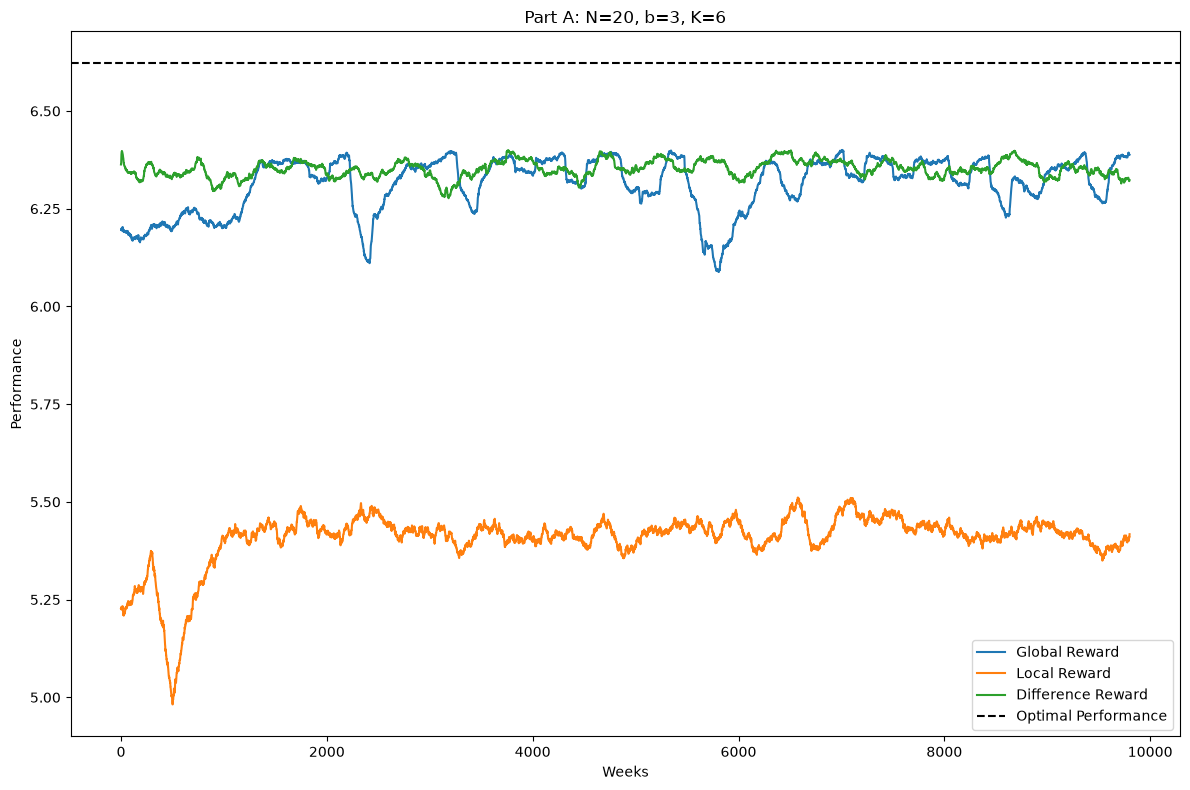

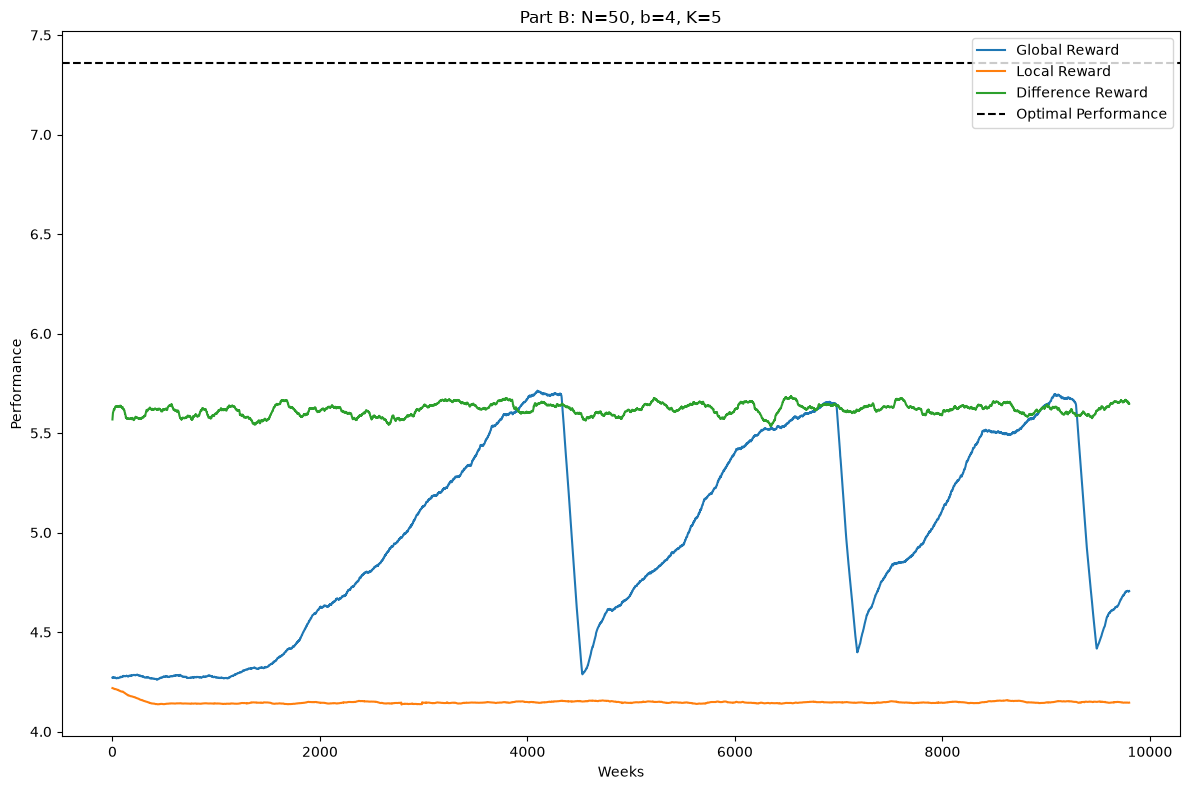

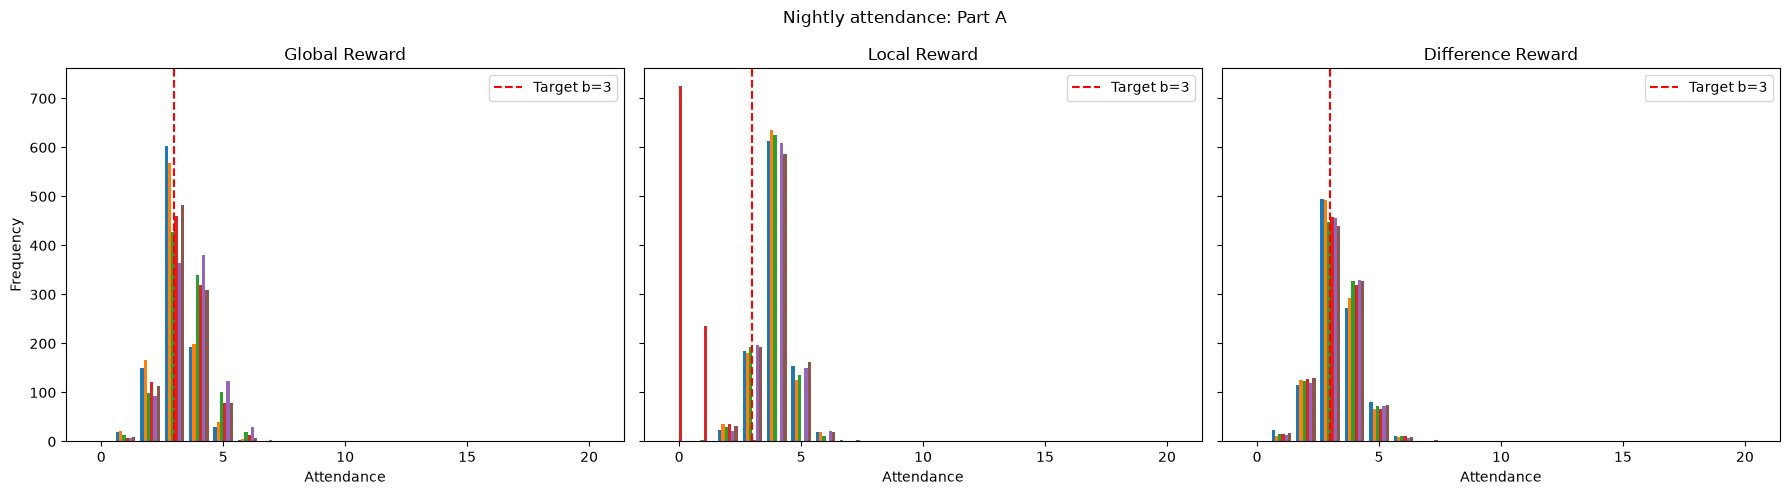

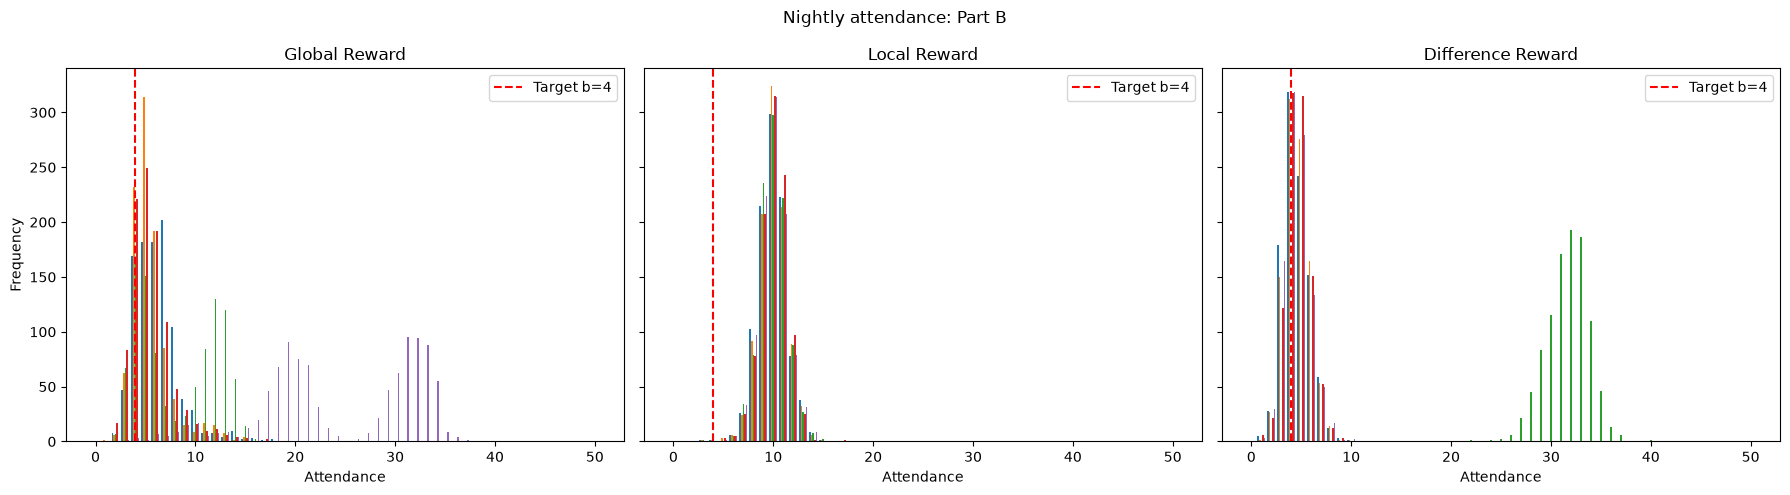

In [9]:
# Perform the simulations
params = [{"N": 20, "b": 3, "K": 6},{"N": 50, "b": 4, "K": 5},]
results = {}
for part, param_set in enumerate(params, start=65):
    for reward_type in ['global', 'local', 'difference']:
        performance, record = simulate(**param_set, reward_type=reward_type)
        results[(part, reward_type)] = (performance, record)

# Plots
for part, param_set in enumerate(params, start=65):
    plt.figure(figsize=(12, 8))
    for reward_type in ['global', 'local', 'difference']:
        performance, _ = results[(part, reward_type)]
        smoothed_perf = np.convolve(performance, np.ones(200)/200, mode='valid')
        plt.plot(smoothed_perf, label=f'{reward_type.capitalize()} Reward')
    
    plt.axhline(param_set["K"] * param_set["b"] / np.e, color="black", linestyle="--", label="Optimal Performance")
    plt.xlabel("Weeks")
    plt.ylabel("Performance")
    plt.title(f"Part {chr(part)}: N={param_set['N']}, b={param_set['b']}, K={param_set['K']}")
    plt.legend()
    plt.tight_layout()
    plt.show()

# Histograms
for part, param_set in enumerate(params, start=65):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
    
    for ax, reward_type in zip(axes, ['global', 'local', 'difference']):
        attendance = results[(part, reward_type)][1]
        
        final_weeks = attendance[int(0.9 * len(attendance)):]  # Last 10% of weeks
        ax.hist(final_weeks, bins=np.arange(-0.5, param_set["N"] + 1.5, 1))
        ax.axvline(param_set["b"], color="red", linestyle="--", label=f"Target b={param_set['b']}")
        ax.set_title(f"{reward_type.capitalize()} Reward")
        ax.set_xlabel("Attendance")
        ax.legend()
        
    axes[0].set_ylabel("Frequency")
    fig.suptitle(f"Nightly attendance: Part {chr(part)}")
    plt.tight_layout()
    plt.show()